# 📊 01. Análisis Exploratorio Inicial (EDA) - Segmentación de Clientes
Este notebook recoge el análisis exploratorio inicial sobre el conjunto completo `data/Train.csv` (8,068 registros), con el objetivo de comprender la estructura general del dataset, la presencia de perfiles coincidentes, el equilibrio de clases y la distribución de las variables antes de generar la partición estratificada (`train_70`, `val_15`, `test_15`).

---

## 1. Carga de Datos e Infraestructura 📦
**Descripción:**  
Configuración del entorno de visualización (`seaborn` y `matplotlib`) y carga del archivo `data/Train.csv` desde el repositorio local (incluyendo descarga bajo demanda vía `kagglehub` únicamente si el archivo no existe en `data/`, y descartando `Test.csv` conforme a la decisión `D-006`).

In [1]:
import os
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración del estilo visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Ruta local de Train.csv (descartamos Test.csv según decisión D-006)
os.makedirs('data', exist_ok=True)
ruta_train = "data/Train.csv"

# Importar kagglehub solo si es necesario descargar Train.csv
if not os.path.exists(ruta_train):
    import kagglehub
    print("No se encontró data/Train.csv localmente. Descargando desde Kaggle...")
    path = kagglehub.dataset_download("kaushiksuresh147/customer-segmentation")
    shutil.copy(os.path.join(path, "Train.csv"), ruta_train)
    print("¡Descarga y copia completadas en data/Train.csv!")
else:
    print("El archivo data/Train.csv ya existe en el repositorio. Cargando localmente...")

# Cargar el dataset completo (8,068 registros)
train_df = pd.read_csv(ruta_train)

print(f"Dataset Train.csv listo: {train_df.shape[0]} filas y {train_df.shape[1]} columnas.")
train_df.head()

El archivo data/Train.csv ya existe en el repositorio. Cargando localmente...
Dataset Train.csv listo: 8068 filas y 11 columnas.


,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A


## 2. Inspección General, Diagnóstico de Nulos y Perfiles Repetidos 🔎
**Descripción:**  
Diagnóstico descriptivo de las 8,068 observaciones de `Train.csv`:
1. **Estructura y valores nulos:** Revisión de tipos de datos, cardinalidad y porcentaje de valores faltantes (las decisiones de imputación se tomarán posteriormente sobre `train_70` tras el split para evitar fuga de datos).
2. **Perfiles repetidos vs. duplicados reales:** Comprobación de filas con idénticas características (`features` excluyendo `ID` y `Segmentation`). Aunque existen clientes que comparten exactamente el mismo perfil demográfico, sus identificadores (`ID`) están distanciados y más de la mitad de estos grupos pertenecen a segmentos distintos, por lo que son clientes reales diferentes y se conservan íntegros.

In [2]:
# 1. Resumen único de tipos, valores nulos y cardinalidad
info_df = pd.DataFrame({
    'Tipo': train_df.dtypes,
    'Valores Nulos': train_df.isnull().sum(),
    '% Nulos': (train_df.isnull().sum() / len(train_df) * 100).round(2),
    'Valores Únicos': train_df.nunique()
})

print("--- RESUMEN DE VARIABLES EN TRAIN.CSV ---")
display(info_df)

print("\n--- ESTADÍSTICOS DESCRIPTIVOS (NUMÉRICAS) ---")
display(train_df.drop(columns=['ID']).describe().round(2))

# 2. Clientes con el mismo perfil: ¿son duplicados reales?
print("\n--- ANÁLISIS DE PERFILES REPETIDOS ---")
features = [c for c in train_df.columns if c not in ('ID', 'Segmentation')]

repetidos = train_df[train_df.duplicated(subset=features, keep=False)].copy()
repetidos['perfil'] = repetidos.groupby(features, dropna=False).ngroup()

grupos = repetidos.groupby('perfil').agg(
    n_clientes=('ID', 'size'),
    n_segmentos=('Segmentation', 'nunique'),
    id_min=('ID', 'min'),
    id_max=('ID', 'max'),
)

print(f"Filas que comparten perfil con otra fila: {len(repetidos)} "
      f"({len(repetidos) / len(train_df):.1%}) en {len(grupos)} perfiles distintos")
print(f"Filas sobrantes si se eliminaran (mismo perfil): "
      f"{train_df.duplicated(subset=features).sum()}")
print(f"Filas sobrantes si se eliminaran (mismo perfil y mismo segmento): "
      f"{train_df.duplicated(subset=features + ['Segmentation']).sum()}")
print(f"Perfiles con segmentos distintos: {(grupos['n_segmentos'] > 1).sum()} de {len(grupos)}")
print(f"Distancia mediana entre IDs del mismo perfil: "
      f"{(grupos['id_max'] - grupos['id_min']).median():.0f}")

print("\nPerfiles más repetidos:")
display(
    repetidos.groupby(features, dropna=False)['Segmentation']
    .agg(n_clientes='size', segmentos=lambda s: dict(s.value_counts()))
    .sort_values('n_clientes', ascending=False)
    .head(5)
)

--- RESUMEN DE VARIABLES EN TRAIN.CSV ---


,Tipo,Valores Nulos,% Nulos,Valores Únicos
ID,int64,0,0.00,8068
Gender,str,0,0.00,2
Ever_Married,str,140,1.74,2
Age,int64,0,0.00,67
Graduated,str,78,0.97,2
Profession,str,124,1.54,9
Work_Experience,float64,829,10.28,15
Spending_Score,str,0,0.00,3
Family_Size,float64,335,4.15,9
Var_1,str,76,0.94,7



--- ESTADÍSTICOS DESCRIPTIVOS (NUMÉRICAS) ---


,Age,Work_Experience,Family_Size
count,8068.00,7239.00,7733.00
mean,43.47,2.64,2.85
std,16.71,3.41,1.53
min,18.00,0.00,1.00
25%,30.00,0.00,2.00
50%,40.00,1.00,3.00
75%,53.00,4.00,4.00
max,89.00,14.00,9.00



--- ANÁLISIS DE PERFILES REPETIDOS ---
Filas que comparten perfil con otra fila: 1283 (15.9%) en 549 perfiles distintos
Filas sobrantes si se eliminaran (mismo perfil): 734
Filas sobrantes si se eliminaran (mismo perfil y mismo segmento): 417
Perfiles con segmentos distintos: 291 de 549
Distancia mediana entre IDs del mismo perfil: 3064

Perfiles más repetidos:


n_clientes  \
Gender Ever_Married Age Graduated Profession Work_Experience Spending_Score Family_Size Var_1               
Male   No           23  No        Healthcare 1.0             Low            4.0         Cat_6           7   
Female No           51  Yes       Artist     0.0             Low            1.0         Cat_6           6   
Male   No           21  No        Healthcare 1.0             Low            4.0         Cat_6           6   
                    20  No        Healthcare 1.0             Low            4.0         Cat_6           6   
                    22  No        Healthcare 0.0             Low            4.0         Cat_6           6   

                                                                                                              segmentos  
Gender Ever_Married Age Graduated Profession Work_Experience Spending_Score Family_Size Var_1                            
Male   No           23  No        Healthcare 1.0             Low            4.0         Cat_6                  {'D': 7}  
Female No           51  Yes       Artist     0.0             Low            1.0         Cat_6  {'B': 3, 'A': 2, 'C': 1}  
Male   No           21  No        Healthcare 1.0             Low            4.0         Cat_6                  {'D': 6}  
                    20  No        Healthcare 1.0             Low            4.0         Cat_6                  {'D': 6}  
                    22  No        Healthcare 0.0             Low            4.0         Cat_6                  {'D': 6}

### Análisis de Perfiles Repetidos y Duplicados Exactos 👥🔍
**Descripción:**  
En la inspección inicial se comprobó que `ID` tiene 8,068 valores únicos (no existen registros duplicados por identificador de cliente). Sin embargo, al tratarse de variables mayoritariamente discretas y categóricas, es necesario verificar si existen clientes distintos que comparten exactamente las mismas características (`features` excluyendo `ID` y `Segmentation`) y si pertenecen al mismo segmento o a segmentos diferentes.

Este diagnóstico permite confirmar que no se trata de errores de carga duplicados, sino de perfiles demográficos coincidentes en la población, evitando eliminar registros válidos antes de realizar la partición estratificada.

In [3]:
# Clientes con el mismo perfil: ¿son duplicados reales?
features = [c for c in train_df.columns if c not in ('ID', 'Segmentation')]

repetidos = train_df[train_df.duplicated(subset=features, keep=False)].copy()
repetidos['perfil'] = repetidos.groupby(features, dropna=False).ngroup()

grupos = repetidos.groupby('perfil').agg(
    n_clientes=('ID', 'size'),
    n_segmentos=('Segmentation', 'nunique'),
    id_min=('ID', 'min'),
    id_max=('ID', 'max'),
)

print(f"Filas que comparten perfil con otra fila: {len(repetidos)} "
      f"({len(repetidos) / len(train_df):.1%}) en {len(grupos)} perfiles distintos")
print(f"Filas sobrantes si se eliminaran (mismo perfil): "
      f"{train_df.duplicated(subset=features).sum()}")
print(f"Filas sobrantes si se eliminaran (mismo perfil y mismo segmento): "
      f"{train_df.duplicated(subset=features + ['Segmentation']).sum()}")
print(f"Perfiles con segmentos distintos: {(grupos['n_segmentos'] > 1).sum()} de {len(grupos)}")
print(f"Distancia mediana entre IDs del mismo perfil: "
      f"{(grupos['id_max'] - grupos['id_min']).median():.0f}")

print("\nPerfiles más repetidos:")
display(
    repetidos.groupby(features, dropna=False)['Segmentation']
    .agg(n_clientes='size', segmentos=lambda s: dict(s.value_counts()))
    .sort_values('n_clientes', ascending=False)
    .head(5)
)

Filas que comparten perfil con otra fila: 1283 (15.9%) en 549 perfiles distintos
Filas sobrantes si se eliminaran (mismo perfil): 734
Filas sobrantes si se eliminaran (mismo perfil y mismo segmento): 417
Perfiles con segmentos distintos: 291 de 549
Distancia mediana entre IDs del mismo perfil: 3064

Perfiles más repetidos:


n_clientes  \
Gender Ever_Married Age Graduated Profession Work_Experience Spending_Score Family_Size Var_1               
Male   No           23  No        Healthcare 1.0             Low            4.0         Cat_6           7   
Female No           51  Yes       Artist     0.0             Low            1.0         Cat_6           6   
Male   No           21  No        Healthcare 1.0             Low            4.0         Cat_6           6   
                    20  No        Healthcare 1.0             Low            4.0         Cat_6           6   
                    22  No        Healthcare 0.0             Low            4.0         Cat_6           6   

                                                                                                              segmentos  
Gender Ever_Married Age Graduated Profession Work_Experience Spending_Score Family_Size Var_1                            
Male   No           23  No        Healthcare 1.0             Low            4.0         Cat_6                  {'D': 7}  
Female No           51  Yes       Artist     0.0             Low            1.0         Cat_6  {'B': 3, 'A': 2, 'C': 1}  
Male   No           21  No        Healthcare 1.0             Low            4.0         Cat_6                  {'D': 6}  
                    20  No        Healthcare 1.0             Low            4.0         Cat_6                  {'D': 6}  
                    22  No        Healthcare 0.0             Low            4.0         Cat_6                  {'D': 6}

## 3. Análisis Univariado (Distribución de Variables) 📈
**Descripción:**  
Exploración visual descriptiva de la variable objetivo (`Segmentation`), las variables numéricas (`Age`, `Work_Experience`, `Family_Size`) y las variables categóricas (`Gender`, `Ever_Married`, `Graduated`, `Spending_Score`, `Var_1`, `Profession`) sobre `Train.csv`.

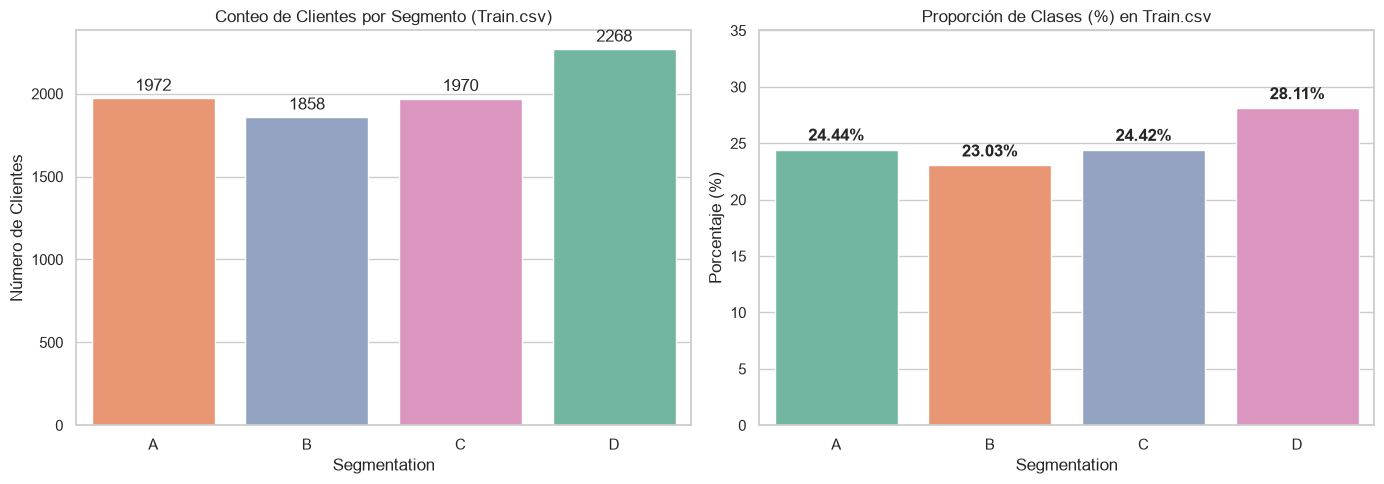

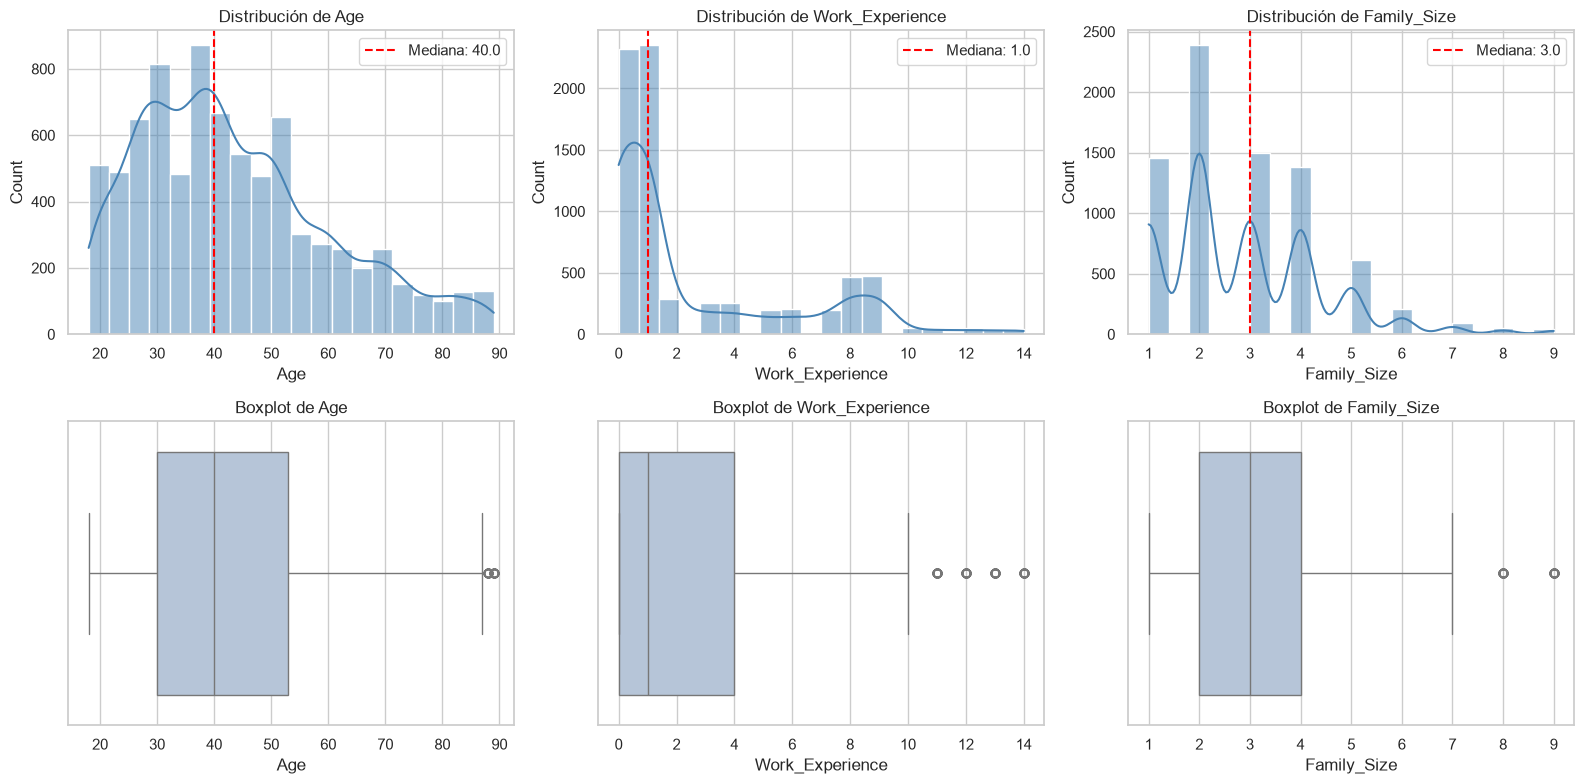

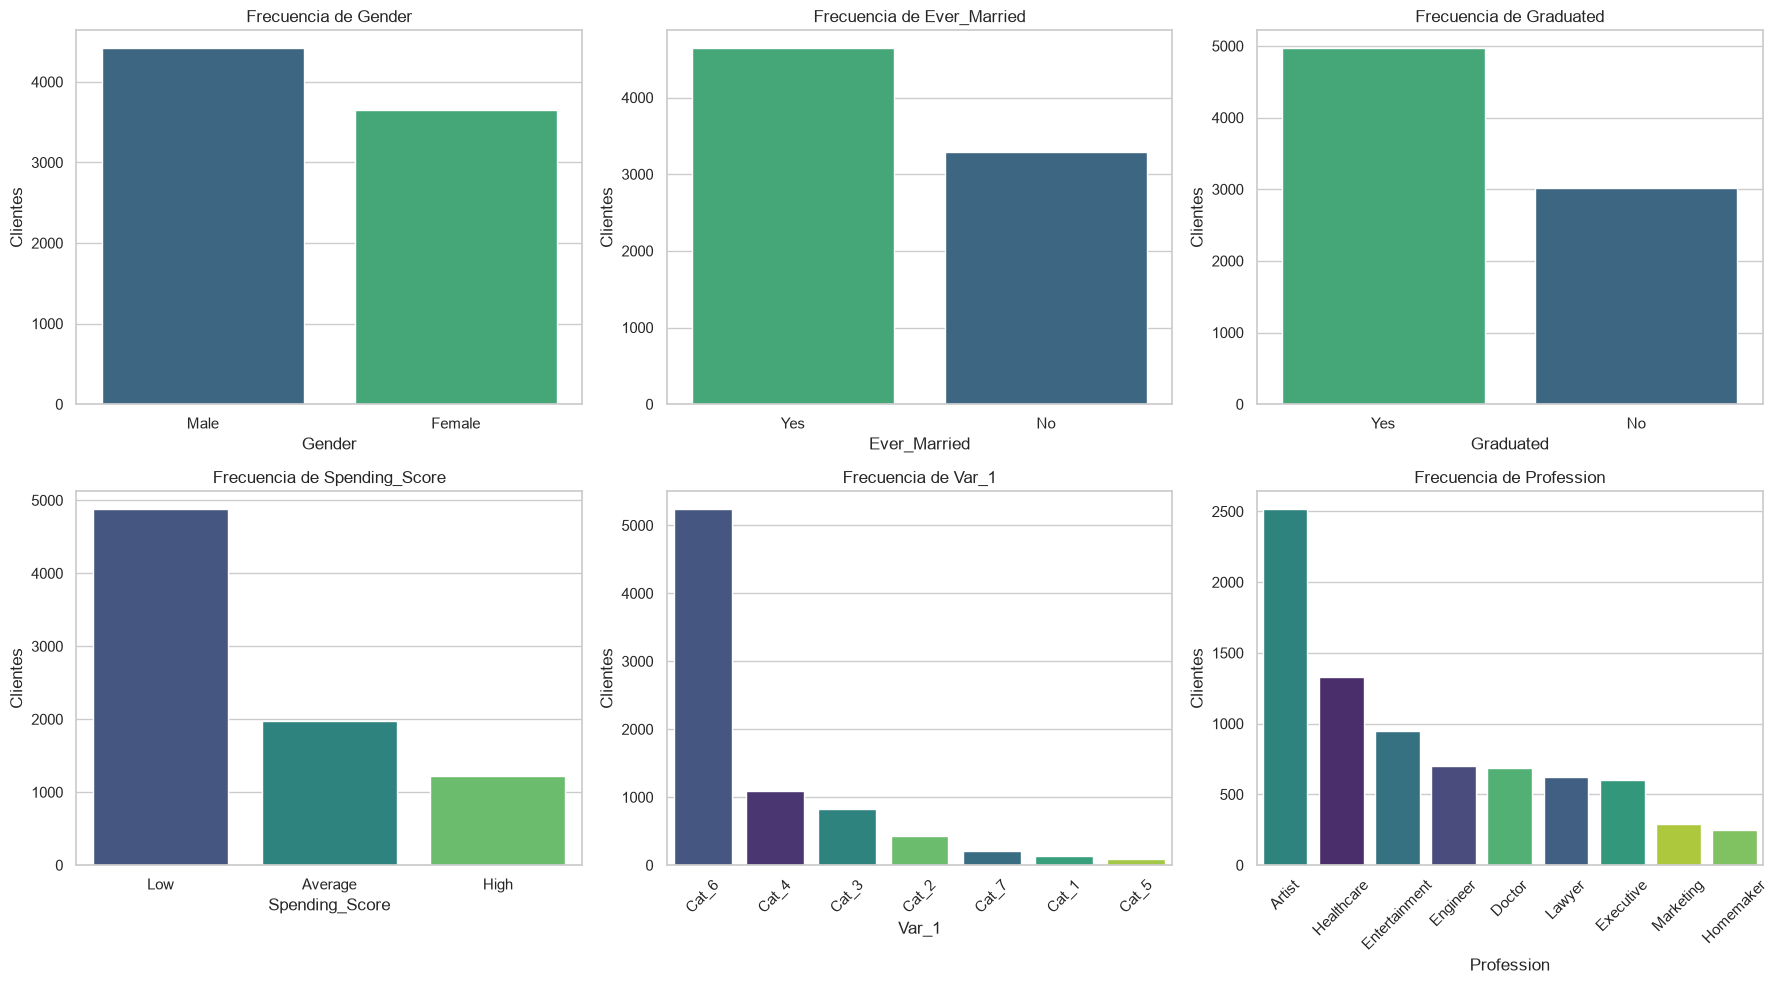

In [4]:
# 1. Distribución de la variable objetivo (Segmentation)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order_seg = ['A', 'B', 'C', 'D']

sns.countplot(
    data=train_df, x='Segmentation', order=order_seg,
    ax=axes[0], palette='Set2', hue='Segmentation', legend=False
)
axes[0].set_title('Conteo de Clientes por Segmento (Train.csv)')
axes[0].set_ylabel('Número de Clientes')
for container in axes[0].containers:
    axes[0].bar_label(container, padding=3)

seg_pct = train_df['Segmentation'].value_counts(normalize=True).reindex(order_seg) * 100
sns.barplot(
    x=seg_pct.index, y=seg_pct.values,
    ax=axes[1], palette='Set2', hue=seg_pct.index, legend=False
)
axes[1].set_title('Proporción de Clases (%) en Train.csv')
axes[1].set_ylabel('Porcentaje (%)')
axes[1].set_ylim(0, 35)
for i, v in enumerate(seg_pct.values):
    axes[1].text(i, v + 0.8, f"{v:.2f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# 2. Distribución de variables numéricas (Histogramas + Boxplots)
num_cols = ['Age', 'Work_Experience', 'Family_Size']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for i, col in enumerate(num_cols):
    sns.histplot(train_df[col].dropna(), kde=True, ax=axes[0, i], color='steelblue', bins=20)
    axes[0, i].axvline(train_df[col].median(), color='red', linestyle='--', label=f"Mediana: {train_df[col].median():.1f}")
    axes[0, i].set_title(f'Distribución de {col}')
    axes[0, i].legend()
    
    sns.boxplot(x=train_df[col].dropna(), ax=axes[1, i], color='lightsteelblue')
    axes[1, i].set_title(f'Boxplot de {col}')

plt.tight_layout()
plt.show()

# 3. Distribución de variables categóricas
cat_cols = ['Gender', 'Ever_Married', 'Graduated', 'Spending_Score', 'Var_1', 'Profession']
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    order = train_df[col].value_counts().index
    sns.countplot(
        data=train_df, x=col, order=order,
        ax=axes[i], palette='viridis', hue=col, legend=False
    )
    axes[i].set_title(f'Frecuencia de {col}')
    axes[i].set_ylabel('Clientes')
    if col in ['Profession', 'Var_1']:
        axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 4. Generación del Split Estratificado (`train_70`, `val_15`, `test_15`) ✂️
**Descripción:**  
Partición estratificada reproducible (`random_state=42`) sobre `Train.csv` en proporción **70% Train (`5,647` filas) / 15% Validation (`1,210` filas) / 15% Test (`1,211` filas)**, generando siempre los tres archivos en `data/` con sus valores nulos intactos y nombres sin colisión de mayúsculas (`D-006`).  

> **Nota técnica (`D-007`):** Esta generación queda temporalmente en este notebook para desbloquear el trabajo inmediato del equipo y se migrará posteriormente a un módulo dedicado dentro de `src/` al ensamblar el `Pipeline`.

In [5]:
from sklearn.model_selection import train_test_split

ruta_train_70 = "data/train_70.csv"
ruta_val_15 = "data/val_15.csv"
ruta_test_15 = "data/test_15.csv"

# Generar y exportar siempre el split estratificado 70/15/15 con nulos intactos
train_70, temp_df = train_test_split(
    train_df, test_size=0.30, random_state=42, stratify=train_df['Segmentation']
)
val_15, test_15 = train_test_split(
    temp_df, test_size=0.50, random_state=42, stratify=temp_df['Segmentation']
)

train_70.to_csv(ruta_train_70, index=False)
val_15.to_csv(ruta_val_15, index=False)
test_15.to_csv(ruta_test_15, index=False)
print("¡Partición 70/15/15 generada y exportada en data/ con nulos intactos!\n")

# Verificación de integridad: tamaños, nulos y proporciones de clase
for nombre, ruta in [('train_70', ruta_train_70), ('val_15', ruta_val_15), ('test_15', ruta_test_15)]:
    df_check = pd.read_csv(ruta)
    dist = (df_check['Segmentation'].value_counts(normalize=True).reindex(['A', 'B', 'C', 'D']) * 100).round(2).to_dict()
    print(f"{nombre}: {df_check.shape[0]} filas | Nulos totales: {df_check.isnull().sum().sum()} | Clases (%): {dist}")

¡Partición 70/15/15 generada y exportada en data/ con nulos intactos!

train_70: 5647 filas | Nulos totales: 1098 | Clases (%): {'A': 24.44, 'B': 23.04, 'C': 24.42, 'D': 28.1}
val_15: 1210 filas | Nulos totales: 240 | Clases (%): {'A': 24.46, 'B': 23.06, 'C': 24.38, 'D': 28.1}
test_15: 1211 filas | Nulos totales: 244 | Clases (%): {'A': 24.44, 'B': 22.96, 'C': 24.44, 'D': 28.16}
